Fit results: N0=2002.57, lambda=205.88
Log scale plot generated. Interaction length lambda = 205.88


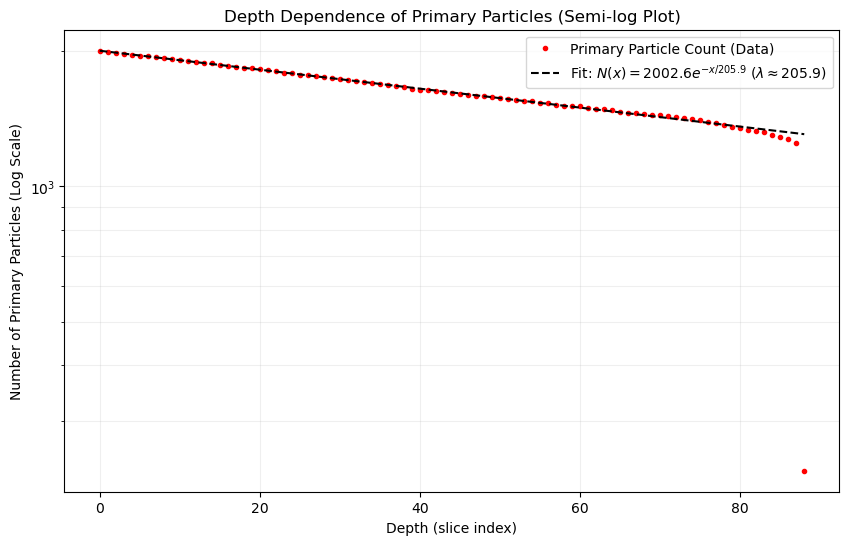

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

# Load data
df = pd.read_csv('carbonEdep.csv')
df.columns = [c.strip() for c in df.columns]

# Filter data to include only positive values for log scale
# The drop to 0 at the end of the range cannot be plotted on a log scale.
df_active = df[df['primaries'] > 0]

# Fit parameters from previous step (calculated again for consistency)
def exponential_decay(x, N0, lam):
    return N0 * np.exp(-x / lam)
# 1. 縦軸（primaries）の値が 1500 以上 2000 以下のデータを抽出
mask = (df_active['primaries'] >= 1500) & (df_active['primaries'] <= 2000)
df_filtered = df_active[mask]

# 2. フィルタリング後のデータを使ってフィッティング
# データが空だとエラーになるため、データが存在するかチェックすると安全です
if len(df_filtered) > 0:
    popt, _ = curve_fit(
        exponential_decay, 
        df_filtered['copyNo'], 
        df_filtered['primaries'], 
        p0=[2000, 1800]
    )
    N0_fit, lam_fit = popt
    print(f"Fit results: N0={N0_fit:.2f}, lambda={lam_fit:.2f}")
else:
    print("指定された範囲にデータが存在しません。")

#from scipy.optimize import curve_fit
#popt, _ = curve_fit(exponential_decay, df_active['copyNo'], df_active['primaries'], p0=[2000, 1800])
#N0_fit, lam_fit = popt

# Plotting
plt.figure(figsize=(10, 6))
plt.semilogy(df_active['copyNo'], df_active['primaries'], 'ro', markersize=3, label='Primary Particle Count (Data)')
plt.semilogy(df_active['copyNo'], exponential_decay(df_active['copyNo'], *popt), 
             'k--', label=rf'Fit: $N(x) = {N0_fit:.1f} e^{{-x/{lam_fit:.1f}}}$ ($\lambda \approx {lam_fit:.1f}$)')

plt.xlabel('Depth (slice index)')
plt.ylabel('Number of Primary Particles (Log Scale)')
plt.title('Depth Dependence of Primary Particles (Semi-log Plot)')
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.legend()

# Save image
plt.savefig('primary_depth_log.png')

print(f"Log scale plot generated. Interaction length lambda = {lam_fit:.2f}")